# DBLP Full Benchmark Evaluation

Compare QueryBloom Full with the DBLP test benchmark using `kg-benchmark-eval`. Configure the endpoint and pinned model values below, then run cells in order. Each visualization is in its own cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import yaml
from IPython.display import HTML, display
from tqdm.auto import tqdm

from kg_benchmark_eval import (
    Benchmark,
    CacheConfig,
    Evaluator,
    MetricSelection,
    Ontology,
    SparqlEndpoint,
    balance_benchmarks,
    plots,
)
from kg_benchmark_eval.encoders import SentenceTransformerEncoder

plt.style.use("seaborn-v0_8-whitegrid")

ANALYSIS_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "new_data").is_dir() and (path / "kg-index").is_dir()
)
OUTPUT_DIR = ANALYSIS_ROOT / "figures" / "kg-benchmark-eval" / "dblp"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GENERATED_PATH = ANALYSIS_ROOT / "new_data" / "dblp-full.yaml"
BASELINE_PATH = ANALYSIS_ROOT / "new_data" / "dblp-test.jsonl"
BALANCE_SEED = 42
MODEL_ID = "BAAI/bge-large-en-v1.5"
MODEL_REVISION = "d4aa6901d3a41ba39fb536a557fa166f842b0e09"
CLASSIFICATION_URL = "https://qlever.dev/api/dblp"
CLASSIFICATION_SNAPSHOT = "qlever-dblp-live"
EXECUTION_URL = CLASSIFICATION_URL
EXECUTION_SNAPSHOT = CLASSIFICATION_SNAPSHOT

progress_bars = {}

def show_progress(stage, completed, total):
    bar = progress_bars.get(stage)
    if bar is None or completed < bar.n:
        if bar is not None:
            bar.close()
        bar = tqdm(total=total, desc=stage.capitalize(), unit="query")
        progress_bars[stage] = bar
    bar.update(completed - bar.n)

In [2]:
with GENERATED_PATH.open(encoding="utf-8") as stream:
    generated_records = yaml.safe_load(stream)

if not isinstance(generated_records, list):
    raise ValueError(f"Expected a list of records in {GENERATED_PATH}")

for record in generated_records:
    if isinstance(record, dict) and "id" in record:
        record["id"] = str(record["id"])

generated = Benchmark.from_records(
    generated_records,
    name="QueryBloom (Full)",
    question_key="text",
    query_key="query",
    normalization="standard",
)
baseline = Benchmark.from_jsonl(
    BASELINE_PATH,
    name="DBLP test",
    normalization="standard",
)
generated, baseline = balance_benchmarks(generated, baseline, seed=BALANCE_SEED)
print(f"{generated.name}: {generated.size} queries")
print(f"{baseline.name}: {baseline.size} queries")

QueryBloom (Full): 85 queries
DBLP test: 85 queries


In [3]:
ontology = Ontology.from_directory(ANALYSIS_ROOT / "kg-index", kg="dblp")
classification_endpoint = SparqlEndpoint(
    url=CLASSIFICATION_URL,
    snapshot_id=CLASSIFICATION_SNAPSHOT,
)
execution_endpoint = SparqlEndpoint(
    url=EXECUTION_URL,
    snapshot_id=EXECUTION_SNAPSHOT,
)
encoder = SentenceTransformerEncoder(
    model_id=MODEL_ID,
    revision=MODEL_REVISION,
    device="cpu",
)

with Evaluator(
    ontology=ontology,
    classification_endpoint=classification_endpoint,
    execution_endpoint=execution_endpoint,
    encoder=encoder,
    cache=CacheConfig(ANALYSIS_ROOT / "cache" / "kg-benchmark-eval" / "dblp"),
    progress=show_progress,
) as evaluator:
    generated_result = evaluator.evaluate(generated, metrics=MetricSelection.all())
    baseline_result = evaluator.evaluate(baseline, metrics=MetricSelection.all())

comparison = generated_result.compare(baseline_result)

Preprocessing:   0%|          | 0/85 [00:00<?, ?query/s]

Execution:   0%|          | 0/271 [00:00<?, ?query/s]

Preprocessing:   0%|          | 0/85 [00:00<?, ?query/s]

Execution:   0%|          | 0/162 [00:00<?, ?query/s]

SPARQL request to https://qlever.dev/api/dblp failed
Traceback (most recent call last):
  File "/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/querybloom/analyze/kg-benchmark-eval/src/kg_benchmark_eval/execution.py", line 95, in execute
    response.raise_for_status()
  File "/Users/essamwisam/miniconda3/envs/m1/lib/python3.10/site-packages/httpx/_models.py", line 829, in raise_for_status
    raise HTTPStatusError(message, request=request, response=self)
httpx.HTTPStatusError: Client error '400 Bad Request' for url 'https://qlever.dev/api/dblp'
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/400
Recording failed SPARQL observation: Client error '400 Bad Request' for url 'https://qlever.dev/api/dblp'
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/400
Failed SPARQL observation for query_id=test_940, evaluation_index=61, source=/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/querybloom/analyze/new_data

In [4]:
display(comparison.to_dataframe())
print("Generated diagnostics:", len(generated_result.diagnostics))
print("Baseline diagnostics:", len(baseline_result.diagnostics))

,benchmark,metric_id,value,status
0,QueryBloom (Full),complexity.column_count_std,1.5839,ok
1,QueryBloom (Full),complexity.column_counts,"[6, 6, 4, 3, 5, 3, 2, 2, 6, 3, 1, 4, 2, 4, 1, ...",ok
2,QueryBloom (Full),complexity.operator_count_std,1.5815,ok
3,QueryBloom (Full),complexity.operator_counts,"[3, 4, 7, 3, 5, 4, 2, 3, 2, 4, 2, 4, 3, 4, 4, ...",ok
4,QueryBloom (Full),complexity.row_count_std,45.2838,ok
...,...,...,...,...
63,DBLP test,diversity.structural.property_hill_2,3.0916,ok
64,DBLP test,diversity.structural.property_mean_per_query,1.5529,ok
65,DBLP test,diversity.structural.property_richness,9,ok
66,DBLP test,diversity.structural.unique_template_ratio,0.5176,ok


Generated diagnostics: 0
Baseline diagnostics: 8


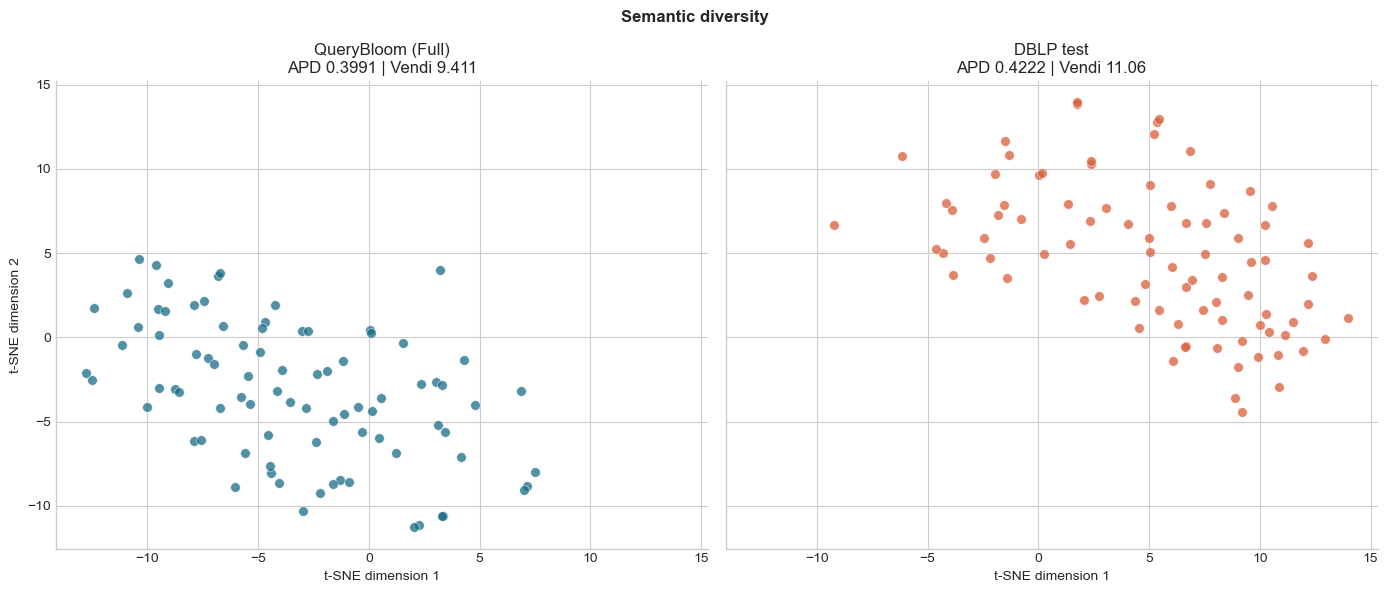

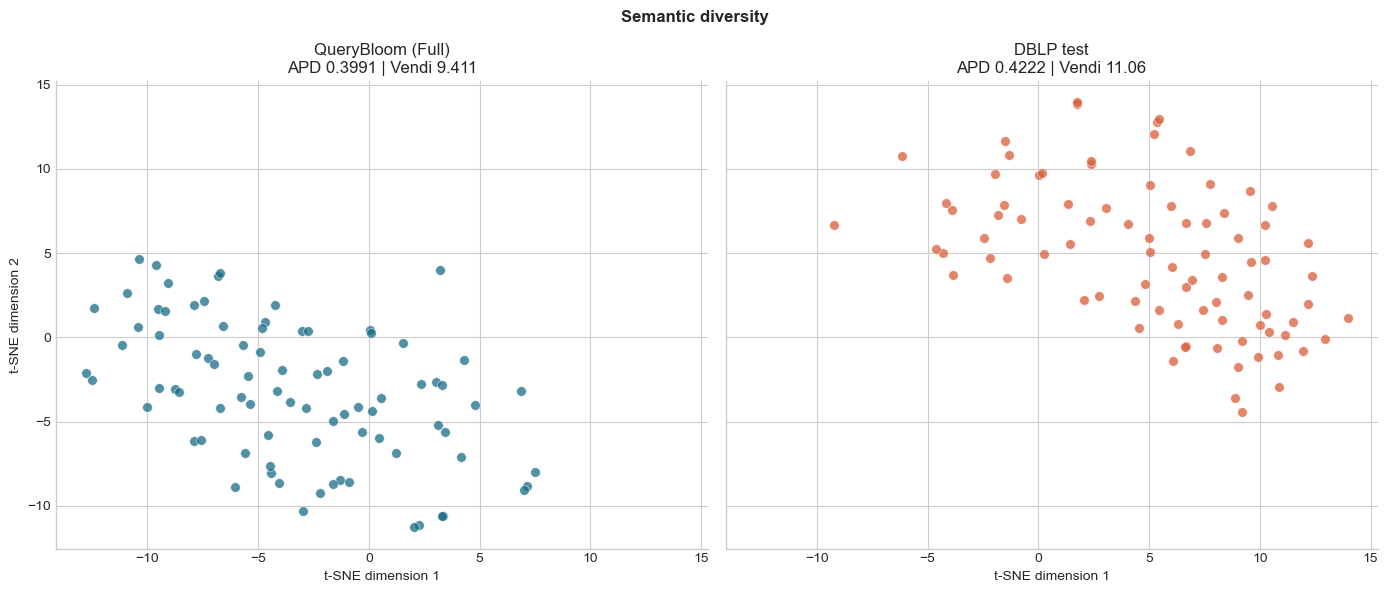

In [5]:
semantic_figure = plots.semantic_space(
    comparison,
    trim_outlier_pct=1,
    seed=42,
)
semantic_figure

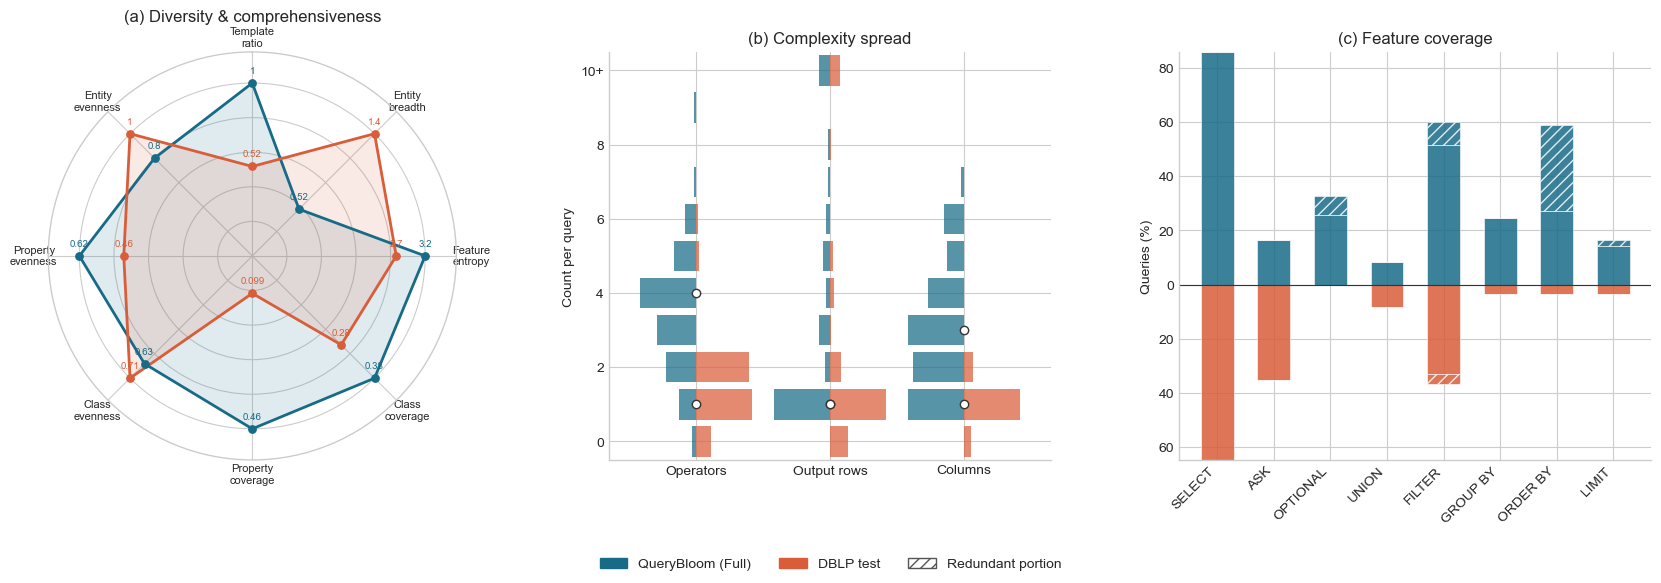

In [11]:
structural_figure = plots.structural_diversity(
    comparison,
    complexity="histogram",
    redundancy_hatching=True,
)
structural_figure

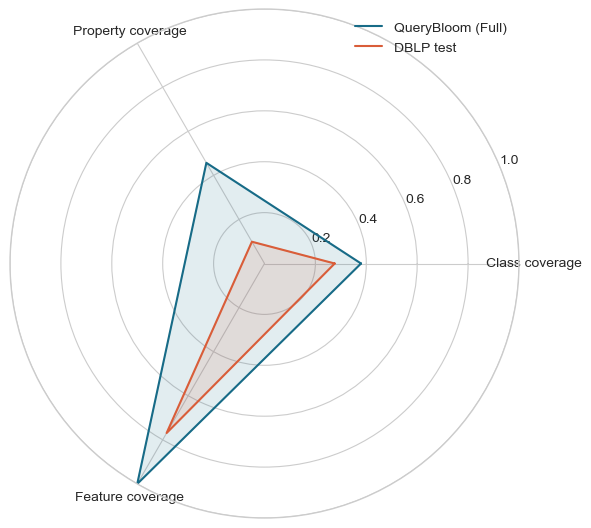

In [7]:
comprehensiveness_figure = plots.comprehensiveness(comparison)
comprehensiveness_figure

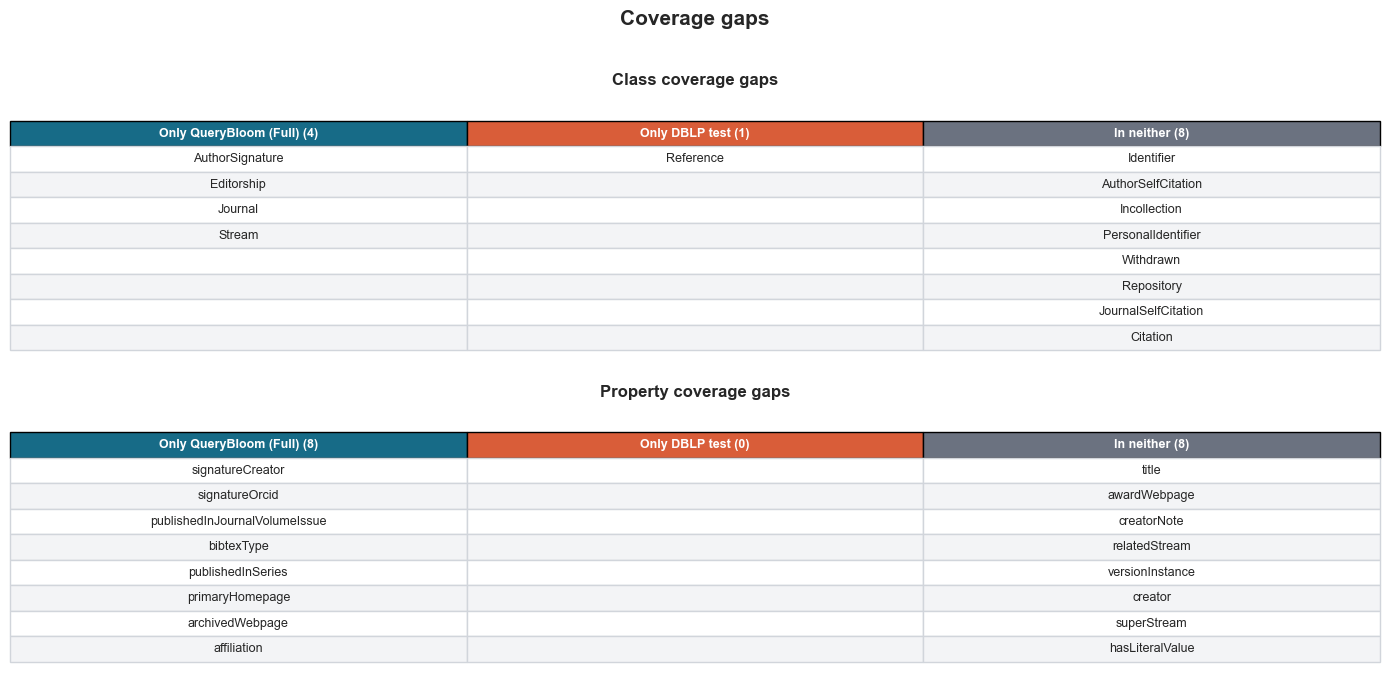

In [8]:
coverage_gaps_figure = plots.coverage_gaps(
    comparison,
    sample_size=8,
    seed=42,
)
coverage_gaps_figure

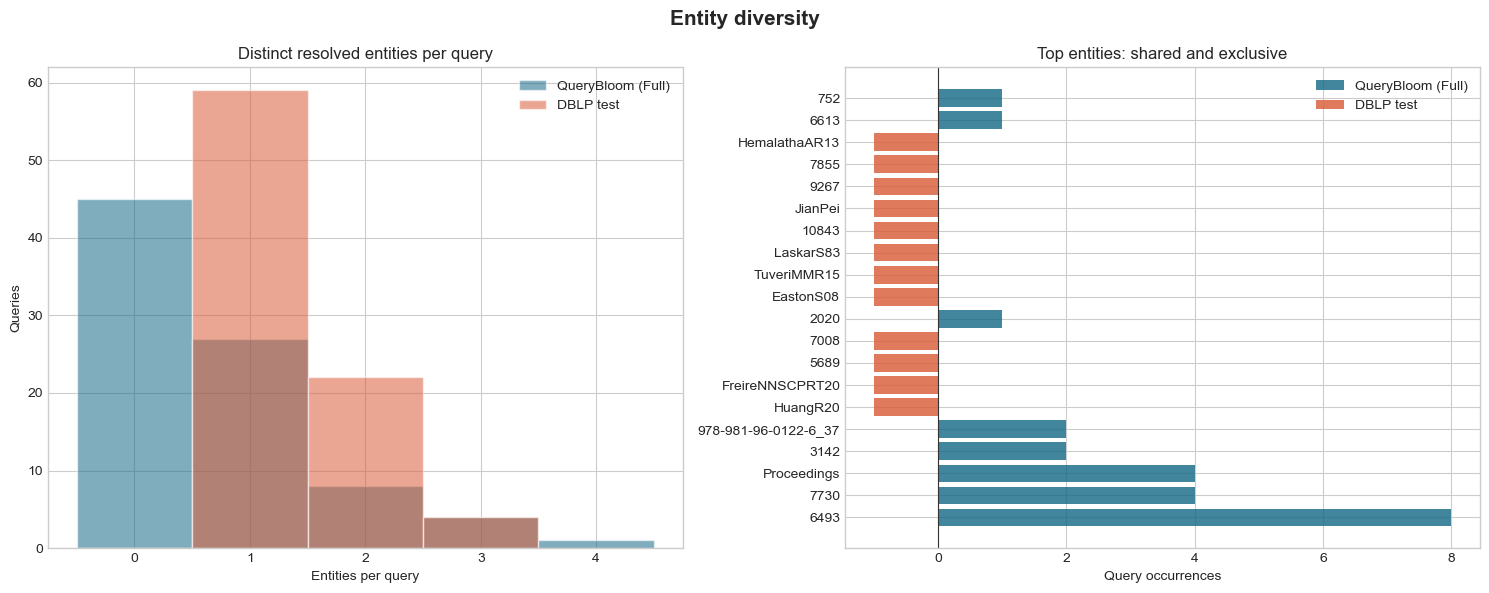

In [9]:
entities_figure = plots.entities(comparison, top_n=20)
entities_figure

In [10]:
display(HTML(plots.redundancy_examples(generated_result, limit=5)))